# Part 4 - Evaluation and comparison
**Notebook 4 of 4.** Needs Parts 1-3 first (it reads their tables from `results/`).

The rule-based part produced **events** (stops, slow steps). The clustering produced
**episodes** (windows where the line stays in one signal pattern). If both point at the
same place, the finding is stronger. Where clustering points somewhere the rules do not,
it is a **review window** - maybe a normal steady state, maybe something the rules were
not built to see. There are no labelled correct answers in this data, so no method can
claim a proven accuracy; agreement between two different methods is the best evidence available.

Imports, the overlap helper once more, and all result tables from Parts 1-3, so the evaluation has everything in one place.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES_DIR = '../results'
FIG_DIR = '../results/figures'


def overlap(a0, a1, b0, b1):
    # seconds the periods a0-a1 and b0-b1 have in common
    return max(0.0, min(a1, b1) - max(a0, b0))


# the tables written by Parts 1-3
stops = pd.read_csv(RES_DIR + '/stops.csv')
slow = pd.read_csv(RES_DIR + '/slow_steps.csv')
cycles = pd.read_csv(RES_DIR + '/cycles.csv')
robot = pd.read_csv(RES_DIR + '/robot_waits.csv')
done = pd.read_csv(RES_DIR + '/completed_parts.csv')
loss = pd.read_csv(RES_DIR + '/loss_per_equipment.csv', index_col=0)['lost_s']
quality = pd.read_csv(RES_DIR + '/data_quality.csv')
gaps = pd.read_csv(RES_DIR + '/logging_gaps.csv')
curtain = pd.read_csv(RES_DIR + '/curtain_both_plcs.csv')
scan = pd.read_csv(RES_DIR + '/cluster_scan.csv')
episodes = pd.read_csv(RES_DIR + '/cluster_episodes.csv')
labels = pd.read_csv(RES_DIR + '/cluster_labels.csv')
BEST_K = int(scan.loc[scan['sampled_silhouette'].idxmax(), 'k'])
CYCLE_NORMAL = cycles.loc[cycles['clean'], 'dur_s'].median()
print('loaded the tables from Parts 1-3; best k =', BEST_K)


loaded the tables from Parts 1-3; best k = 8


This block compares the two methods. For each of the 10 longest cluster episodes we measure how much it overlaps with the stops and slow steps found by the rules. Where they overlap, both methods saw the same problem; episodes without a match are windows worth a manual look.

In [2]:
# the 10 longest cluster episodes against the rule-based events
top = episodes.sort_values('dwell_ms', ascending=False).head(10).copy()
top['stop_overlap_s'] = [sum(overlap(r.start_s, r.end_s, s.start_s, s.end_s)
                             for s in stops.itertuples())
                         for r in top.itertuples()]
top['slow_overlap_s'] = [sum(overlap(r.start_s, r.end_s, s.start_s, s.end_s)
                             for s in slow.itertuples())
                         for r in top.itertuples()]
top['match'] = np.where(top['stop_overlap_s'] > 0, 'contains a stop',
                np.where(top['slow_overlap_s'] > 0, 'contains a slow step',
                         'no rule-based event (review window)'))
n_match = int(((top['stop_overlap_s'] > 0) | (top['slow_overlap_s'] > 0)).sum())
top.round(3).to_csv(RES_DIR + '/comparison_top_windows.csv', index=False)
top[['cluster', 'start_s', 'end_s', 'dwell_ms', 'censored',
     'stop_overlap_s', 'slow_overlap_s', 'match']].round(2)


,cluster,start_s,end_s,dwell_ms,censored,stop_overlap_s,slow_overlap_s,match
24,0,142.21,172.30,30090.0,NaN,0.0,0.00,no rule-based event (review window)
32,0,196.69,224.91,28220.0,NaN,0.0,0.00,no rule-based event (review window)
43,5,316.46,341.28,24820.0,NaN,0.0,5.18,contains a slow step
58,5,460.78,485.52,24735.0,NaN,4.9,14.81,contains a stop
11,3,61.03,84.83,23800.0,NaN,0.0,9.79,contains a slow step
33,3,224.91,246.24,21335.0,NaN,0.0,0.00,no rule-based event (review window)
52,5,400.60,419.14,18530.0,NaN,0.0,0.26,contains a slow step
35,7,253.64,271.74,18105.0,NaN,8.9,29.99,contains a stop
10,0,45.14,61.03,15895.0,NaN,0.0,0.00,no rule-based event (review window)
12,0,84.83,100.56,15725.0,NaN,0.0,0.00,no rule-based event (review window)


The same cluster chart as in Part 3, now with the rule-based events on top: orange bands for stops, purple lines for slow steps. The printed lines below say in plain numbers how many of the longest episodes match a rule-based event.

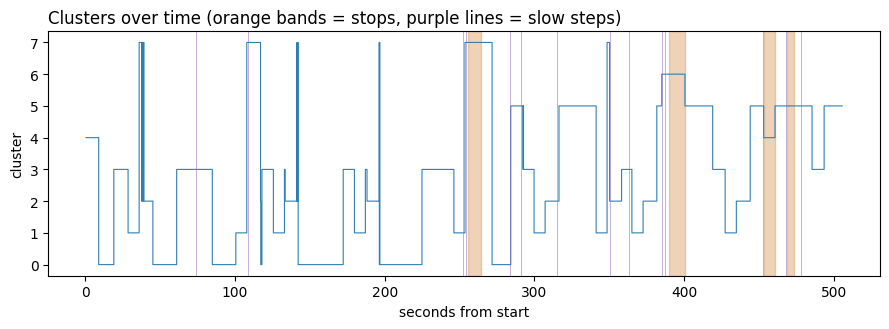

Of the 10 longest cluster episodes:
  2 contain a stop and slow steps paused by it
  0 contain a stop
  3 contain a slow step
  5 have no rule-based event -> windows to review

Cross-check with the teammate (his own grid and pipeline): his three candidate
windows (about 18:22:15, 18:25:28 and 18:27:39) sit in the same regions as the
cycle-2 slow step and two of the light-curtain stops found here.


In [3]:
# chart: clusters over time with the rule-based events on top
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.step(labels['ms'] / 1000, labels['cluster'], where='post', lw=0.8, color='#2f7fb3')
for st in stops.itertuples():
    ax.axvspan(st.start_s, st.end_s, color='#c9701a', alpha=0.3)
for r in slow.itertuples():
    ax.axvline(r.start_s, color='#8a5fc0', lw=0.7, alpha=0.5)
ax.set_xlabel('seconds from start')
ax.set_ylabel('cluster')
ax.set_yticks(range(BEST_K))
ax.set_title('Clusters over time (orange bands = stops, purple lines = slow steps)',
             loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/comparison_clusters_over_time.png', dpi=150)
plt.show()

# what the comparison says, in plain numbers
both = int(((top['stop_overlap_s'] > 0) & (top['slow_overlap_s'] > 0)).sum())
stop_only = int(((top['stop_overlap_s'] > 0) & (top['slow_overlap_s'] == 0)).sum())
slow_only = int(((top['stop_overlap_s'] == 0) & (top['slow_overlap_s'] > 0)).sum())
none = int(((top['stop_overlap_s'] == 0) & (top['slow_overlap_s'] == 0)).sum())
print(f'Of the {len(top)} longest cluster episodes:')
print(f'  {both} contain a stop and slow steps paused by it')
print(f'  {stop_only} contain a stop')
print(f'  {slow_only} contain a slow step')
print(f'  {none} have no rule-based event -> windows to review')
print()
print('Cross-check with the teammate (his own grid and pipeline): his three candidate')
print('windows (about 18:22:15, 18:25:28 and 18:27:39) sit in the same regions as the')
print('cycle-2 slow step and two of the light-curtain stops found here.')


## Summary

All key numbers from the four parts printed in one place, so the results can be checked without scrolling through every notebook.

In [4]:
slow_by_itself = slow[slow['cause'] == 'slow by itself']
print(f"Stops: {len(stops)}, total {stops['dur_s'].sum():.1f} s")
print(f'Slow steps: {len(slow)} ({len(slow_by_itself)} slow by themselves, '
      f'{len(slow) - len(slow_by_itself)} paused by a stop)')
print(f'Cycles: {len(cycles)} complete, normal {CYCLE_NORMAL:.1f} s, '
      f"longest {cycles['dur_s'].max():.1f} s")
print('Robot waited in cycles:', robot.loc[robot['robot_waited'], 'cycle'].tolist())
print(f"Completed parts: {len(done)}, long gaps: {int(done['long_gap'].sum())} "
      f"(with stop inside: {int((done['long_gap'] & (done['stop_in_gap_s'] > 0)).sum())})")
print('Lost time per equipment (s):', loss.round(1).to_dict())
print(f"Logging gaps over 1 s: Siemens {quality.loc[1, 'gaps_over_1s']}, "
      f"Beckhoff {quality.loc[0, 'gaps_over_1s']} | "
      f"slow steps explainable by a gap: {int(slow['could_be_gap'].sum())}")
print(f'Clustering: k = {BEST_K}, {len(episodes)} episodes, '
      f"silhouette {scan.loc[scan['k'] == BEST_K, 'sampled_silhouette'].iloc[0]:.3f} "
      f'(weak) | longest 10 episodes: {n_match} overlap rule-based events')


Stops: 4, total 31.8 s
Slow steps: 14 (9 slow by themselves, 5 paused by a stop)
Cycles: 8 complete, normal 53.4 s, longest 68.2 s
Robot waited in cycles: [7]
Completed parts: 10, long gaps: 3 (with stop inside: 2)
Lost time per equipment (s): {'Robot': 2.0, 'Drilling station': 6.3, 'Warehouse': 29.9, 'Stops (all stations at once)': 31.8}
Logging gaps over 1 s: Siemens 4, Beckhoff 1 | slow steps explainable by a gap: 0
Clustering: k = 8, 61 episodes, silhouette 0.154 (weak) | longest 10 episodes: 5 overlap rule-based events


## Conclusions
### Per hypothesis
| | Verdict | Evidence |
|---|---|---|
| **L1** Steps take longer | **Supported** | 14 slow steps. 9 are slow by themselves: warehouse belt 9 to 12 times normal (3 steps, 21.9 s lost), drill 5.1 times (5.1 s instead of 1.0 s), warehouse arm towards the belt 2.5 to 2.6 times (3 steps), one slow step at the drilling station (1.4 times), and the robot's grip once (2.0 s extra). 5 more are only paused by a stop. |
| **L2** Robot transfers cause waiting | **Partly supported** | The robot's own move is steady (6.6 to 6.7 s in all 8 cycles). In cycle 7 the robot waited 6.0 s, but for the slow warehouse belt. In 3 of 9 transfers the oven starts 14 to 27 s after the robot's release (others under 2 s); the cause is unknown because the dictionary has no "ready" signal. |
| **L3** Short pauses increase the time between parts | **Partly supported** | 10 completed parts, median gap 45.7 s, 3 long gaps (71.7 to 73.9 s). Two contain a stop (8.9 s and 12.5 s). The stops explain only part of the extra time. The long gap without a stop (71.7 s) has a 16.4 s delay between a robot release and the oven start. Only 10 events, so treat as an indication. |
| **L4** One station causes more delay | **Supported, name to confirm** | Own slow steps: warehouse 29.9 s (belt 21.9 s), drilling station 6.3 s, robot 2.0 s. The light-curtain and operator-screen stops (31.8 s) hit all stations at once. The dictionary calls the second station "drilling station", the project text "milling machine". |

### What the combined model adds
The clustering (Part 3) independently marks long episodes, and **5 of its 10 longest episodes
overlap rule-based events**: the first light-curtain stop together with the steps it paused,
the operator-screen pause, and the cycle-2 slow grip. The teammate's own clustering run, on a
differently built grid, pointed at the same regions again. Two different methods finding the
same places is the strongest evidence this project has.

The other 5 long episodes have **no rule-based event**. They are review windows, not faults:
a long dwell can simply be a normal steady state (the clustering cannot tell). Reviewing those
windows signal by signal, and the oven-delay question from L2/L3, are the open next steps.

### Limits
- The 25 % and 2 s limits, the 5-repeat rule and the cycle definition are my own choices, agreed in the team.
- Outputs that stay on for long periods and the duplicate long-named Beckhoff outputs are not treated as steps.
- Equipment is assigned from the dictionary; there is no labelled ground truth, so no method's accuracy can be proven.
- Durations are measured between recorded timestamps, without grid rounding. The logs still only sample their signals (every 76 / 93 ms), so a true value can differ by up to one sampling interval, and borderline cases (like the robot grip at 2.02 s over the limit) can flip.
- The cluster scores are weak (silhouette 0.15), so clusters are coarse operating states, not confirmed events; k = 8 is a geometry choice.
- Every comparison across the two logs assumes their clocks agree - this was never checked.
- The recording is 8:25 although the documents say 10 minutes.

The last block builds the summary: the verdict for each hypothesis with its key number, and all result tables written into one Excel file with one sheet each. That file is the main deliverable for the report.

In [5]:
summary = pd.DataFrame({
    'hypothesis': ['L1', 'L2', 'L3', 'L4', 'Combined evaluation'],
    'verdict': ['Supported', 'Partly supported', 'Partly supported',
                'Supported, station name to confirm', 'Methods agree on the main windows'],
    'key number': [f'{len(slow)} slow steps ({len(slow_by_itself)} by themselves)',
                   f"robot waited {robot['extra_wait_s'].max():.1f} s once (cycle 7), "
                   'for the belt',
                   f"{int(done['long_gap'].sum())} long gaps, "
                   f"{int((done['long_gap'] & (done['stop_in_gap_s'] > 0)).sum())} "
                   'with a stop inside',
                   f"warehouse {loss['Warehouse']:.1f} s, drilling station "
                   f"{loss['Drilling station']:.1f} s, stops {stops['dur_s'].sum():.1f} s",
                   f'{n_match} of {len(top)} longest cluster episodes overlap '
                   'rule-based events']})

with pd.ExcelWriter(RES_DIR + '/performance_loss_findings.xlsx', engine='openpyxl') as writer:
    summary.to_excel(writer, sheet_name='Summary', index=False)
    slow.round(2).to_excel(writer, sheet_name='L1 slow steps', index=False)
    robot.round(2).to_excel(writer, sheet_name='L2 robot', index=False)
    pd.read_csv(RES_DIR + '/oven_after_release.csv').round(2).to_excel(
        writer, sheet_name='L2 robot to oven', index=False)
    done.round(1).to_excel(writer, sheet_name='L3 completed parts', index=False)
    loss.round(1).to_frame('lost_s').to_excel(writer, sheet_name='L4 per equipment')
    quality.to_excel(writer, sheet_name='Data quality', index=False)
    gaps.round(2).to_excel(writer, sheet_name='Logging gaps', index=False)
    curtain.round(3).to_excel(writer, sheet_name='Curtain both PLCs', index=False)
    stops.round(2).to_excel(writer, sheet_name='Stops', index=False)
    cycles.round(1).to_excel(writer, sheet_name='Cycles', index=False)
    scan.to_excel(writer, sheet_name='Cluster scan', index=False)
    episodes.round(2).to_excel(writer, sheet_name='Cluster episodes', index=False)
    top.round(2).to_excel(writer, sheet_name='Comparison top windows', index=False)
print('written: results/performance_loss_findings.xlsx (14 sheets)')
summary


written: results/performance_loss_findings.xlsx (14 sheets)


,hypothesis,verdict,key number
0,L1,Supported,14 slow steps (9 by themselves)
1,L2,Partly supported,"robot waited 6.0 s once (cycle 7), for the belt"
2,L3,Partly supported,"3 long gaps, 2 with a stop inside"
3,L4,"Supported, station name to confirm","warehouse 29.9 s, drilling station 6.3 s, stop..."
4,Combined evaluation,Methods agree on the main windows,5 of 10 longest cluster episodes overlap rule-...
